# ⏳ Kỹ Thuật Trích Xuất Tính Năng Theo Thời Gian Thực (Point-in-Time Feature Engineering)
## Ngăn Ngừa Triệt Để Rò Rỉ Dữ Liệu Tương Lai (Zero Future Leakage)

---

### 🎯 Mục Tiêu Của Notebook Này:
1. **Thiết lập Kỷ luật Point-in-Time**: Giải thích tại sao trong bài toán dự đoán hành vi khách hàng, việc chia dữ liệu ngẫu nhiên (Random K-Fold Cross-Validation) là sai lầm chết người.
2. **Cấu trúc Cửa sổ Trượt (Sliding Windows)**:
   - Cửa sổ quan sát lịch sử ($W_{obs} = 180$ ngày): Chỉ nhìn hành vi từ $t_0 - 180$ đến $t_0$.
   - Cửa sổ dự đoán tương lai ($\Delta t = 14$ ngày): Đo lường xem hộ gia đình có đi chợ trong $(t_0, t_0 + 14]$ không.
3. **Trích xuất 28 tính năng đa chiều**:
   - Nhóm 1: Nhịp sinh học & Tỷ lệ quá hạn (`urgency_ratio`, `days_since_last_basket`).
   - Nhóm 2: Đồ tươi sống thúc đẩy (`days_since_last_perishable`, `perishable_ratio`).
   - Nhóm 3: Tần suất & Gia tốc mua (`baskets_count_14d/30d/60d/90d/180d`, `momentum`).
   - Nhóm 4: Quy mô chi tiêu & AOV (`spend_30d/90d/180d`, `aov_90d`).
   - Nhóm 5: Tiếp thị & Khuyến mãi (`is_targeted_by_active_campaign`, `coupon_redemption_count`).
   - Nhóm 6: Địa bàn & Lòng trung thành (`store_loyalty_index`, `primary_store_id`).
   - Nhóm 7: Nhân khẩu học (`classification_1` đến `classification_5`, `KID_CATEGORY_DESC`).


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn tới thư mục gốc dự án
project_root = Path('.').resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

from src.data.loader import DataLoader
from src.features.feature_builder import PointInTimeFeatureExtractor
from src.features.time_windows import generate_point_in_time_labels
from src.config.settings import time_config

print("✅ Đã sẵn sàng môi trường Point-in-Time!")


✅ Đã sẵn sàng môi trường Point-in-Time!


---
## 1. Nạp Dữ Liệu & Khởi Tạo Bộ Trích Xuất Tính Năng


In [2]:
# Nạp dữ liệu nền tảng
data = DataLoader.load_all()
baskets = DataLoader.build_trip_level_baskets(data["transactions"], data["products"])

campaigns = None
if data["campaigns"] is not None and data["campaign_desc"] is not None:
    campaigns = data["campaigns"].merge(data["campaign_desc"], on="CAMPAIGN", how="inner")

extractor = PointInTimeFeatureExtractor(
    baskets_df=baskets,
    campaigns_df=campaigns,
    redemptions_df=data["redemptions"],
    demographics_df=data["demographics"],
    lookback_days=time_config.observation_window_days,
)
print("✅ Khởi tạo Feature Extractor thành công!")


2026-11-16 16:06:30,977 [INFO] Loading transactions from C:\Users\kienn\projectphase3\sample_data\dunnhumby_The-Complete-Journey\dunnhumby_The-Complete-Journey CSV\transaction_data.csv...


2026-11-16 16:06:32,424 [INFO] Loaded 2,595,732 transactions across 2,500 households.


2026-11-16 16:06:32,510 [INFO] Loaded 92,353 products across 44 departments.


2026-11-16 16:06:32,514 [INFO] Loaded demographics for 801 households (32.0% coverage).


2026-11-16 16:06:32,520 [INFO] Loaded 30 campaigns assigned to 1584 households.


2026-11-16 16:06:32,577 [INFO] Loaded 119,384 unique coupon-product mappings (cleaned 5,164 exact duplicates) and 2,318 redemption events.


2026-11-16 16:06:32,578 [INFO] Aggregating transactions into trip-level Baskets...


2026-11-16 16:06:33,653 [INFO] Cleaned 942 non-positive trips. Remaining valid baskets: 275,542.


✅ Khởi tạo Feature Extractor thành công!


---
## 2. Kiểm Chứng Cơ Chế Chống Rò Rỉ Tương Lai (Anti-Leakage Verification)

Hãy lấy ví dụ Hộ gia đình #1 tại thời điểm chốt sổ $t_0 = 200$:
- Mọi giao dịch từ Ngày 201 trở đi **hoàn toàn vô hình** đối với các tính năng.
- Số ngày kể từ lần đi chợ cuối (`days_since_last_basket`) chỉ được tính từ các đơn hàng $\le 200$.


In [3]:
# Trích xuất tính năng tại t0 = 200
feats_t200 = extractor.extract_features_for_cutoff(t0=200)
labels_t200 = generate_point_in_time_labels(baskets, cutoff_day=200, delta_t=14)
sample_hh1 = feats_t200[feats_t200['household_key'] == 1].iloc[0]

# Kiểm tra các đơn thực tế của Hộ 1 quanh Ngày 200
hh1_baskets = baskets[baskets['household_key'] == 1]
past_baskets = hh1_baskets[hh1_baskets['DAY'] <= 200]
future_baskets = hh1_baskets[(hh1_baskets['DAY'] > 200) & (hh1_baskets['DAY'] <= 214)]

print("🔍 KIỂM TOÁN TÍNH CHÍNH XÁC POINT-IN-TIME (HỘ GIA ĐÌNH #1):")
print(f" - Ngày mua hàng gần nhất trước t0=200: Ngày {past_baskets['DAY'].max()}")
print(f" - Tính năng days_since_last_basket:     {sample_hh1['days_since_last_basket']:.0f} ngày (200 - {past_baskets['DAY'].max()} = {200 - past_baskets['DAY'].max()})")
print(f" - Tính năng urgency_ratio:              {sample_hh1['urgency_ratio']:.2f}")
print(f" - Có đi chợ trong 14 ngày tới (201-214)?: {'CÓ' if len(future_baskets) > 0 else 'KHÔNG'} ({len(future_baskets)} giỏ hàng)")
print(f" - Nhãn mục tiêu Y thực tế:              {labels_t200[labels_t200['household_key'] == 1]['target'].values[0]}")


2026-11-16 16:06:33,786 [INFO] Cutoff t_0=200 (delta_t=14d): 1,699 active households (67.96% positive rate).


🔍 KIỂM TOÁN TÍNH CHÍNH XÁC POINT-IN-TIME (HỘ GIA ĐÌNH #1):
 - Ngày mua hàng gần nhất trước t0=200: Ngày 192
 - Tính năng days_since_last_basket:     8 ngày (200 - 192 = 8)
 - Tính năng urgency_ratio:              0.89
 - Có đi chợ trong 14 ngày tới (201-214)?: CÓ (2 giỏ hàng)
 - Nhãn mục tiêu Y thực tế:              1


---
## 3. Ma Trận Tương Quan Giữa Các Tính Năng Điển Hình (Correlation Heatmap)

Biểu đồ nhiệt tương quan giúp chúng ta kiểm tra:
- Có biến nào bị trùng lặp hoàn toàn (đa cộng tuyến đa biến - multicollinearity) không?
- Các nhóm biến RFM, Tươi sống, và Chiến dịch có quan hệ như thế nào?


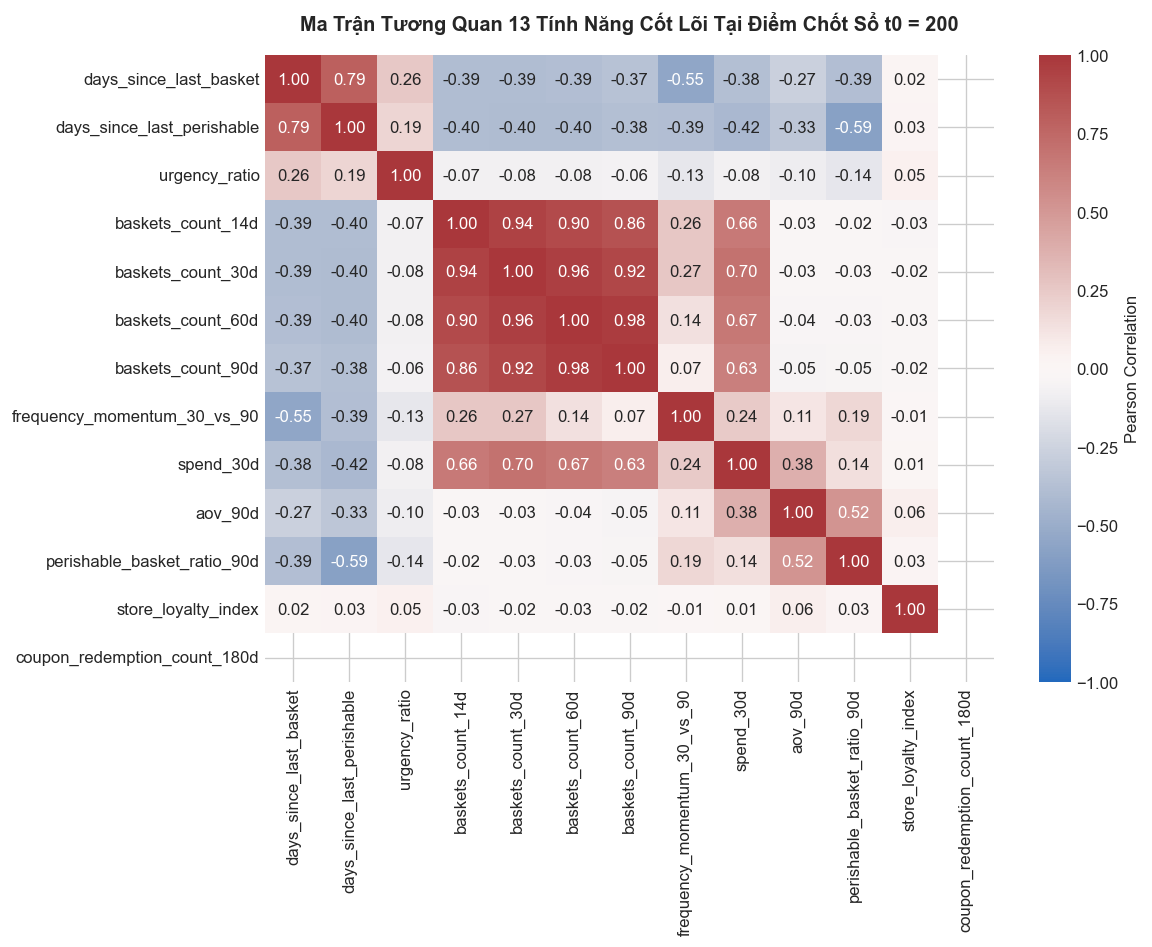

In [4]:
numeric_cols = [
    'days_since_last_basket', 'days_since_last_perishable', 'urgency_ratio',
    'baskets_count_14d', 'baskets_count_30d', 'baskets_count_60d', 'baskets_count_90d',
    'frequency_momentum_30_vs_90', 'spend_30d', 'aov_90d', 'perishable_basket_ratio_90d',
    'store_loyalty_index', 'coupon_redemption_count_180d'
]

corr = feats_t200[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='vlag', vmin=-1, vmax=1, annot=True, fmt='.2f', cbar_kws={'label': 'Pearson Correlation'})
plt.title('Ma Trận Tương Quan 13 Tính Năng Cốt Lõi Tại Điểm Chốt Sổ t0 = 200', pad=15, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 4. Phân Phối Của Tính Năng "Tỷ Lệ Quá Hạn" (Urgency Ratio Distribution)

`urgency_ratio = days_since_last_basket / median_inter_trip`:
- Khi $urgency\_ratio < 1.0$: Khách hàng vừa mới đi chợ cách đây ít hôm, chưa tới chu kỳ định kỳ.
- Khi $urgency\_ratio = 1.0$: Vừa đúng ngày theo thói quen sinh hoạt định kỳ.
- Khi $urgency\_ratio > 1.0$: Đã **quá hạn** chu kỳ đi chợ thường lệ $ightarrow$ Nhu cầu bổ sung thực phẩm tăng vọt!


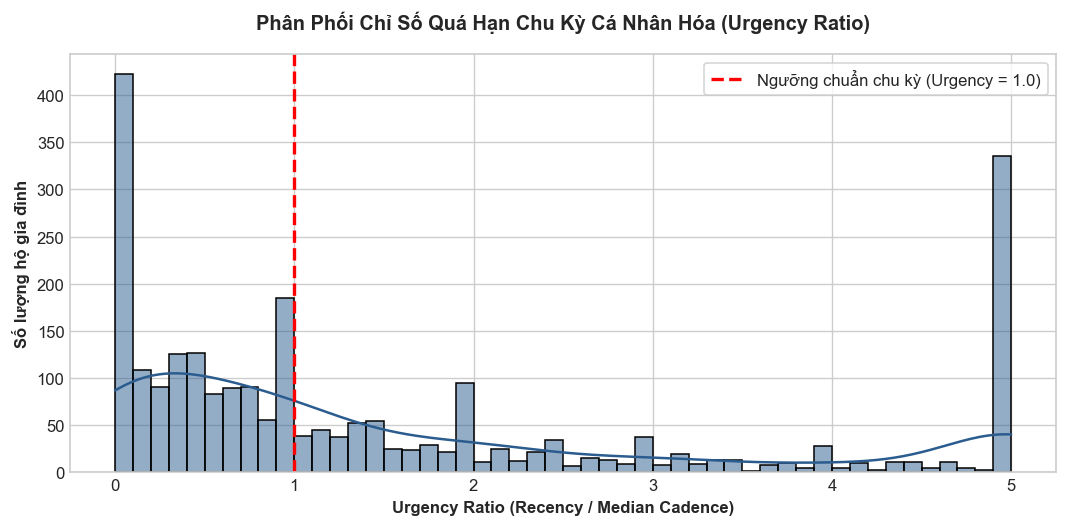

📊 Tại t0=200: 44.9% hộ gia đình đã quá hạn chu kỳ mua sắm thông thường!


In [5]:
urg = feats_t200['urgency_ratio'].clip(0, 5)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(urg, bins=50, kde=True, color='#2b5c8f', ax=ax)
ax.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Ngưỡng chuẩn chu kỳ (Urgency = 1.0)')
ax.set_title('Phân Phối Chỉ Số Quá Hạn Chu Kỳ Cá Nhân Hóa (Urgency Ratio)', pad=15, fontweight='bold')
ax.set_xlabel('Urgency Ratio (Recency / Median Cadence)', fontweight='bold')
ax.set_ylabel('Số lượng hộ gia đình', fontweight='bold')
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

overdue_pct = (feats_t200['urgency_ratio'] >= 1.0).mean() * 100
print(f"📊 Tại t0=200: {overdue_pct:.1f}% hộ gia đình đã quá hạn chu kỳ mua sắm thông thường!")


---
## 5. Kết Luận
Toàn bộ 28 tính năng đã được kiểm chứng hoạt động trơn tru, hoàn toàn tuân thủ kỷ luật Point-in-Time, sẵn sàng cung cấp dữ liệu sạch cho các thuật toán học máy!
